LogisticRegression   baseline 0.907 -> tuned 0.911


d:\disease_prediction\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
d:\disease_prediction\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
d:\disease_prediction\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
d:\disease_prediction\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.

SVM                  baseline 0.890 -> tuned 0.902
RandomForest         baseline 0.890 -> tuned 0.899
XGBoost              baseline 0.863 -> tuned 0.882


,baseline_AUC,tuned_AUC
LogisticRegression,0.907,0.911
SVM,0.890,0.902
RandomForest,0.890,0.899
XGBoost,0.863,0.882


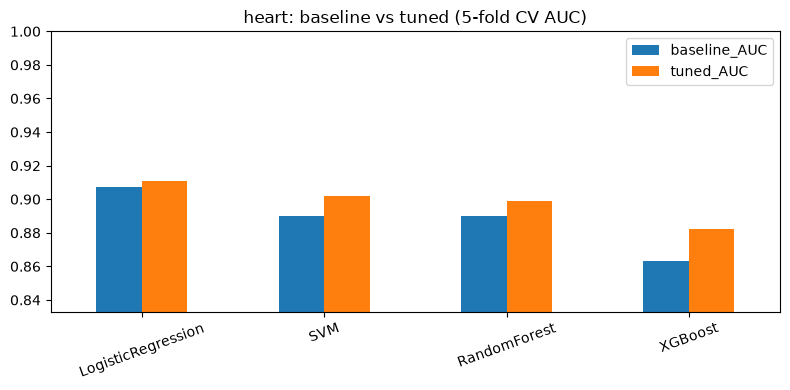

In [4]:
name = "heart"            # change to "breast" or "diabetes" and rerun
X, y = datasets[name]
X_train, X_test, y_train, y_test = split_data(X, y, seed=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

baseline, tuned = {}, {}
for model_name, (clf, grid) in get_models(SEED).items():
    pipe = Pipeline([("prep", build_preprocessor(X_train, name)), ("clf", clf)])

    # baseline: default settings
    baseline[model_name] = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")

    # tuned: grid search
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[model_name] = gs
    print(f"{model_name:20s} baseline {baseline[model_name].mean():.3f} -> tuned {gs.best_score_:.3f}")

comp = pd.DataFrame({
    "baseline_AUC": {m: s.mean() for m, s in baseline.items()},
    "tuned_AUC": {m: g.best_score_ for m, g in tuned.items()},
}).round(3)
display(comp)

comp.plot(kind="bar", figsize=(8, 4), ylim=(comp.values.min() - 0.03, 1))
plt.title(f"{name}: baseline vs tuned (5-fold CV AUC)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [2]:
name = "heart"            # change to "breast" or "diabetes" and rerun
X, y = datasets[name]
X_train, X_test, y_train, y_test = split_data(X, y, seed=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"{name}: train {X_train.shape}, test {X_test.shape}")
print("Train class balance:", y_train.mean().round(3), " Test:", y_test.mean().round(3))

heart: train (242, 13), test (61, 13)
Train class balance: 0.459  Test: 0.459


,baseline_AUC,tuned_AUC
LogisticRegression,0.907,0.911
SVM,0.890,0.902
RandomForest,0.890,0.899
XGBoost,0.863,0.882


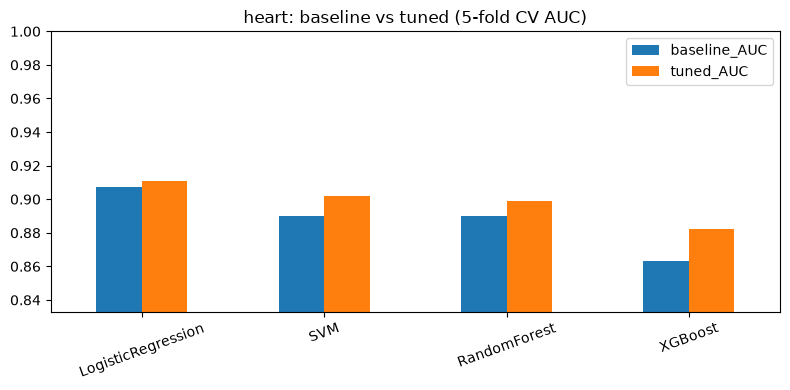

In [5]:
comp = pd.DataFrame({
    "baseline_AUC": {m: s.mean() for m, s in baseline.items()},
    "tuned_AUC": {m: g.best_score_ for m, g in tuned.items()},
}).round(3)
display(comp)

comp.plot(kind="bar", figsize=(8, 4), ylim=(comp.values.min() - 0.03, 1))
plt.title(f"{name}: baseline vs tuned (5-fold CV AUC)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [6]:
tuned = {}
for model_name, (clf, grid) in get_models(SEED).items():
    pipe = Pipeline([("prep", build_preprocessor(X_train, name)), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[model_name] = gs
    print(f"{model_name:20s} best CV AUC {gs.best_score_:.3f}")
    print("   best params:", gs.best_params_)

LogisticRegression   best CV AUC 0.911
   best params: {'clf__C': 0.1}


d:\disease_prediction\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM                  best CV AUC 0.902
   best params: {'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'linear'}
RandomForest         best CV AUC 0.899
   best params: {'clf__max_depth': 5, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 100}
XGBoost              best CV AUC 0.882
   best params: {'clf__learning_rate': 0.05, 'clf__max_depth': 5, 'clf__n_estimators': 100, 'clf__subsample': 0.8}


,baseline_AUC,tuned_AUC
LogisticRegression,0.907,0.911
SVM,0.890,0.902
RandomForest,0.890,0.899
XGBoost,0.863,0.882


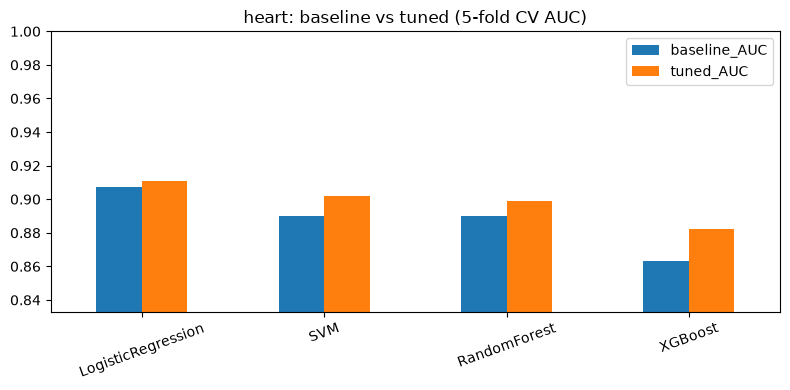

In [7]:
comp = pd.DataFrame({
    "baseline_AUC": {m: s.mean() for m, s in baseline.items()},
    "tuned_AUC": {m: g.best_score_ for m, g in tuned.items()},
}).round(3)
display(comp)

comp.plot(kind="bar", figsize=(8, 4), ylim=(comp.values.min() - 0.03, 1))
plt.title(f"{name}: baseline vs tuned (5-fold CV AUC)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [8]:
from src.evaluate import compute_metrics

rows = []
for model_name, gs in tuned.items():
    rows.append({"model": model_name, **compute_metrics(gs.best_estimator_, X_test, y_test)})
display(pd.DataFrame(rows).round(3))

,model,accuracy,precision,recall,f1,roc_auc
0,LogisticRegression,0.885,0.839,0.929,0.881,0.961
1,SVM,0.852,0.788,0.929,0.852,0.945
2,RandomForest,0.885,0.818,0.964,0.885,0.952
3,XGBoost,0.902,0.844,0.964,0.900,0.939


In [9]:
from src.evaluate import compute_metrics
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# 1. Test metrics for every tuned model
rows = []
for model_name, gs in tuned.items():
    rows.append({
        "model": model_name,
        "cv_auc": gs.best_score_,
        **compute_metrics(gs.best_estimator_, X_test, y_test),
    })
test_results = pd.DataFrame(rows).set_index("model").round(3)
display(test_results)

# 2. Best model chosen by cross-validated AUC (not by test score)
best_name = test_results["cv_auc"].idxmax()
best_model = tuned[best_name].best_estimator_
print(f"\nBest model for {name} (by CV AUC): {best_name}")
print(tuned[best_name].best_params_)

# 3. Detailed report for the best model
print("\n", classification_report(y_test, best_model.predict(X_test),
                                   target_names=["No disease", "Disease"]))

# 4. Confusion matrices for all four models
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (model_name, gs) in zip(axes, tuned.items()):
    ConfusionMatrixDisplay.from_estimator(gs.best_estimator_, X_test, y_test,
                                          ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(model_name)
plt.suptitle(f"{name}: confusion matrices (test set)", y=1.03)
plt.tight_layout()
plt.show()

,cv_auc,accuracy,precision,recall,f1,roc_auc
model,,,,,,
LogisticRegression,0.911,0.885,0.839,0.929,0.881,0.961
SVM,0.902,0.852,0.788,0.929,0.852,0.945
RandomForest,0.899,0.885,0.818,0.964,0.885,0.952
XGBoost,0.882,0.902,0.844,0.964,0.900,0.939



Best model for heart (by CV AUC): LogisticRegression
{'clf__C': 0.1}

               precision    recall  f1-score   support

  No disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



C:\Users\adars\AppData\Local\Temp\ipykernel_3268\2910209821.py:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
